# ① 基本統計手法：t検定（2グループの平均を比べるだけ）

**目的**：実際に研修を受けた働き手の中でも、「余力」があるかないかで職務満足に差が出るかを確認し、
「研修を受けても余力がないと満足度は上がらない」という仮説をシンプルに検証する。

**手順**

1. 研修を受けた回答者（`train` = 1）だけに絞り込む（n = 1,067 / 1,959）
2. その中で、時間的余力（`wrktime_r`）が最上位のグループ／それ以外のグループの2つに分ける
3. 2つのグループそれぞれの職務満足（`satjob1_r`）の平均値を、t検定（対応のない2標本t検定、Welch法）で比較する

使うデータは `gss_qwl_recent_subset.csv`（GSS 1972–2024 累積ファイルからQWL関連60変数を抜き出したもの）。

## 0. 準備：ライブラリの読み込みとデータベースの作成

- `pandas`：表形式のデータを扱う（Excelのシートのようなもの）
- `numpy`：数値計算（平方根などに使う）
- `matplotlib` / `seaborn`：グラフを描く
- `sqlite3`：SQLiteデータベースを扱う（Pythonに最初から入っているので追加インストール不要）

**データの流れ**

このノートブックでは、CSVを毎回読み直すのではなく、**最初に一度だけCSVをSQLiteデータベースに取り込み、
以降の分析はすべてデータベースから読み込む**という形にする。

```
gss_qwl_recent_subset.csv  ──(0-1)──▶  gss_qwl.db  ──(0-2)──▶  df  ──▶  ①②③の分析
```

**なぜデータベースを経由するのか**

- 元のCSVを直接触らずに済むので、うっかり上書きしてしまう事故が起きない
- 「2014年を除外する」といった下ごしらえを1か所に閉じ込められる（分析側で消し忘れる事故を防げる）
- SQLで必要な行・列だけを取り出せる（大きなデータでは、全部読み込まずに済むぶん速い）

**SQLiteとは**：1つのファイル（ここでは `gss_qwl.db`）がそのままデータベースになる、いちばん手軽なデータベース。
サーバーを立てる必要がなく、`to_sql()` で書き込み・`read_sql()` で読み込みができるので、pandasだけで完結する。

### 0-1. CSVをデータベースに取り込む

`gss_qwl_recent_subset.csv` には2014年・2018年・2022年の3波が入っているが、
**2014年は前版設計との接続確認（Info Only）用**で本分析には使わない。ここで落としてから書き込む。

同時に、**中身が1つも入っていない列も落とす**。`trainops`（訓練機会の十分さ）のように2018年より前に廃止された設問は、
残った2波では全員が空欄になる。分析に使えないうえ保存すれば容量も使うので、書き込む前に外しておく。

CSVの空欄（IAP＝該当なし、DK＝わからない、NA＝無回答）は、pandasが自動で欠測値 `NaN` として扱い、
データベースには `NULL` として保存される。

In [321]:
import pandas as pd
import matplotlib as mpl
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sqlite3

mpl.rcParams["font.family"] = ["Hiragino Sans"]

DB_PATH = "gss_qwl.db"   # 作成するデータベースファイルの名前

# --- CSVを読み込む（3波：2014/2018/2022） ---
raw = pd.read_csv("gss_qwl_recent_subset.csv")
print("CSV読み込み直後:", len(raw), "行 ×", raw.shape[1], "列")
print(raw["year"].value_counts().sort_index().to_string())

# --- 2014年（Info Only）を除外する ---
recent = raw[raw["year"] != 2014].copy()
print("\n2014年を除外後:", len(recent), "行")

# --- 中身が1つも入っていない列を落とす ---
empty_cols = [col for col in recent.columns if recent[col].notna().sum() == 0]
recent = recent.drop(columns=empty_cols)
print("全員が空欄だった列を除外:", empty_cols)

# --- データベースに書き込む ---
conn = sqlite3.connect(DB_PATH)

recent.to_sql("gss_qwl", conn, if_exists="replace", index=False)

conn.commit()
conn.close()

print(f"\n{DB_PATH} のテーブル gss_qwl に {len(recent)} 行 × {recent.shape[1]} 列を書き込みました")

CSV読み込み直後: 8430 行 × 60 列
year
2014.0    2538
2018.0    2348
2022.0    3544

2014年を除外後: 5892 行
全員が空欄だった列を除外: ['prestg80', 'lotofsay', 'trainops', 'jbtrain']

gss_qwl.db のテーブル gss_qwl に 5892 行 × 56 列を書き込みました


### 0-2. データベースから読み込む

ここから先の分析は、**すべてこのセルで作る `df` を使う**。CSVはもう参照しない。

`pd.read_sql()` は、書いたSQLの実行結果をそのままデータフレームで返してくれる。
`SELECT * FROM gss_qwl` は「gss_qwl テーブルの全部の列（`*`）・全部の行を取ってくる」という意味である。

In [322]:
conn = sqlite3.connect(DB_PATH)

# テーブルの中身を丸ごと読み込む
df = pd.read_sql("SELECT * FROM gss_qwl", conn)

# ついでに、SQLで年ごとの人数を数えて中身を確認する
#   （pandas の value_counts() と同じことを、SQLで書いたもの）
by_year = pd.read_sql("""
    SELECT year, COUNT(*) AS 人数
    FROM gss_qwl
    GROUP BY year
    ORDER BY year
""", conn)

conn.close()

print("データベースから読み込み:", len(df), "行 ×", df.shape[1], "列")
print(by_year.astype(int).to_string(index=False))
df

データベースから読み込み: 5892 行 × 56 列
 year   人数
 2018 2348
 2022 3544


,year,id,wrkstat,hrs1,wrkslf,wrkgovt,prestg10,age,educ,degree,...,slpprblm,satjob1,emptrain,stress,coninc,conrinc,ballot,wtssall,wtssps,wtssnrps
0,2018.0,1.0,3.0,NaN,2.0,2.0,47.0,43.0,14.0,2.0,...,2.0,2.0,1.0,1.0,NaN,NaN,1.0,2.357493,1.908104,2.244275
1,2018.0,2.0,5.0,NaN,2.0,2.0,22.0,74.0,10.0,1.0,...,NaN,NaN,NaN,NaN,22782.50000,NaN,3.0,0.942997,0.914550,1.095217
2,2018.0,3.0,1.0,40.0,2.0,2.0,61.0,42.0,16.0,3.0,...,2.0,2.0,1.0,3.0,112160.00000,70100.0,2.0,0.942997,0.609109,0.740432
3,2018.0,4.0,1.0,40.0,2.0,2.0,59.0,63.0,16.0,3.0,...,2.0,1.0,2.0,2.0,152135.07879,84120.0,2.0,0.942997,0.642403,0.769342
4,2018.0,5.0,5.0,NaN,2.0,2.0,53.0,71.0,18.0,4.0,...,NaN,NaN,NaN,NaN,152135.07879,NaN,3.0,0.942997,0.396347,0.462239
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5887,2022.0,3541.0,1.0,48.0,2.0,NaN,30.0,22.0,12.0,1.0,...,2.0,2.0,NaN,3.0,17407.50000,NaN,1.0,NaN,1.911362,2.216307
5888,2022.0,3542.0,1.0,50.0,2.0,NaN,61.0,29.0,19.0,4.0,...,2.0,2.0,NaN,2.0,42727.50000,42727.5,1.0,NaN,0.351222,0.398404
5889,2022.0,3543.0,1.0,38.0,2.0,NaN,62.0,32.0,15.0,2.0,...,1.0,1.0,NaN,2.0,88620.00000,52222.5,2.0,NaN,2.722293,3.127414
5890,2022.0,3544.0,1.0,40.0,2.0,NaN,61.0,49.0,17.0,4.0,...,1.0,2.0,1.0,2.0,101280.00000,42727.5,3.0,NaN,2.256331,2.577970


**補足**

- データベースに保存すると、欠測値 `NaN` は `NULL` になり、読み戻すとまた `NaN` に戻る。数値はすべて `REAL`（小数）型になる。
  元のCSVが小数で書かれているためで、そのまま使って問題ない。
- 除外された4列（`prestg80` `lotofsay` `trainops` `jbtrain`）は、いずれも2018年以降は収録がない設問である。
  設計サマリーで「`trainops` は2006年を最後に廃止されたので、能力の代表変数を `emptrain` に変更する」と書かれているのが、まさにこれにあたる。
  **60列 → 56列**になるが、①〜③で使う変数はすべて残っている。
- 0-1のセルは**初回だけ実行すれば十分**である（`gss_qwl.db` はファイルとして残るため）。

- 1つの `.db` ファイルの中に、テーブルはいくつでも置ける。別のデータフレームも残したいときは、テーブル名を変えて同じ `to_sql()` を呼べばよい。
  - 3波すべて（8,430行）：`raw.to_sql("gss_qwl_all", conn, if_exists="replace", index=False)`
  - 加工後の分析用データ（`train` や `wrktime_r` を追加したもの）：`work.to_sql("gss_qwl_work", conn, if_exists="replace", index=False)`
- 必要な行だけ取り出すこともできる。例：2022年のフルタイム被雇用者だけなら
  `pd.read_sql("SELECT * FROM gss_qwl WHERE year = 2022 AND wrkstat = 1 AND wrkslf = 2", conn)`

t検定には `scipy` という統計用のライブラリを使うので、追加で読み込んでおく。

In [323]:
from scipy import stats

print("行数（回答者数）:", len(df))   # 2018年・2022年のみ
print("列数（変数の数）:", df.shape[1])

行数（回答者数）: 5892
列数（変数の数）: 56


In [324]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5892 entries, 0 to 5891
Data columns (total 56 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   year       5892 non-null   float64
 1   id         5892 non-null   float64
 2   wrkstat    5882 non-null   float64
 3   hrs1       3319 non-null   float64
 4   wrkslf     5667 non-null   float64
 5   wrkgovt    2214 non-null   float64
 6   prestg10   5574 non-null   float64
 7   age        5677 non-null   float64
 8   educ       5869 non-null   float64
 9   degree     5892 non-null   float64
 10  sex        5872 non-null   float64
 11  partfull   3910 non-null   float64
 12  satjob     4202 non-null   float64
 13  wksub      3852 non-null   float64
 14  yearsjob   3375 non-null   float64
 15  moredays   3328 non-null   float64
 16  wkvsfam    3396 non-null   float64
 17  learnnew   3375 non-null   float64
 18  overwork   3365 non-null   float64
 19  knowwhat   3379 non-null   float64
 20  myskills   3375 non

In [325]:
df.shape

(5892, 56)

In [326]:
df.columns

Index(['year', 'id', 'wrkstat', 'hrs1', 'wrkslf', 'wrkgovt', 'prestg10', 'age',
       'educ', 'degree', 'sex', 'partfull', 'satjob', 'wksub', 'yearsjob',
       'moredays', 'wkvsfam', 'learnnew', 'overwork', 'knowwhat', 'myskills',
       'respect', 'trustman', 'safehlth', 'proudemp', 'prodctiv', 'wkdecide',
       'toofewwk', 'promteok', 'opdevel', 'hlpequip', 'haveinfo', 'wkfreedm',
       'fringeok', 'supcares', 'promtefr', 'jobsecok', 'suphelp', 'wrktime',
       'cowrkhlp', 'manvsemp', 'trynewjb', 'health1', 'mntlhlth', 'usedup',
       'spvtrfair', 'slpprblm', 'satjob1', 'emptrain', 'stress', 'coninc',
       'conrinc', 'ballot', 'wtssall', 'wtssps', 'wtssnrps'],
      dtype='str')

In [327]:
df.isnull().sum()

year            0
id              0
wrkstat        10
hrs1         2573
wrkslf        225
wrkgovt      3678
prestg10      318
age           215
educ           23
degree          0
sex            20
partfull     1982
satjob       1690
wksub        2040
yearsjob     2517
moredays     2564
wkvsfam      2496
learnnew     2517
overwork     2527
knowwhat     2513
myskills     2517
respect      2519
trustman     2546
safehlth     2527
proudemp     2540
prodctiv     2535
wkdecide     2531
toofewwk     2544
promteok     2576
opdevel      2542
hlpequip     2531
haveinfo     2532
wkfreedm     2533
fringeok     2594
supcares     2613
promtefr     2743
jobsecok     2542
suphelp      2601
wrktime      2537
cowrkhlp     2560
manvsemp     2563
trynewjb     2541
health1      2512
mntlhlth     2580
usedup       2526
spvtrfair    2597
slpprblm     2515
satjob1      2532
emptrain     3537
stress       2526
coninc        630
conrinc      2539
ballot          0
wtssall      3544
wtssps          0
wtssnrps  

In [328]:
df.describe()

,year,id,wrkstat,hrs1,wrkslf,wrkgovt,prestg10,age,educ,degree,...,slpprblm,satjob1,emptrain,stress,coninc,conrinc,ballot,wtssall,wtssps,wtssnrps
count,5892.000000,5892.000000,5882.000000,3319.000000,5667.000000,2214.000000,5574.000000,5677.000000,5869.000000,5892.000000,...,3377.000000,3360.000000,2355.000000,3366.000000,5262.000000,3353.000000,5892.000000,2348.000000,5892.000000,5892.000000
mean,2020.405974,1534.214528,3.054063,40.639349,1.889712,1.797200,44.827054,49.092478,13.957744,1.758316,...,2.291087,1.644048,1.493843,2.943553,50415.640423,38520.017959,1.999830,1.000000,1.000000,1.000000
std,1.958529,947.943605,2.329688,14.271894,0.313276,0.402176,13.600509,18.008330,2.931783,1.240810,...,0.966081,0.726785,0.500068,1.000635,43339.280488,37594.052808,0.815213,0.611458,1.102724,1.098202
min,2018.000000,1.000000,1.000000,0.000000,1.000000,1.000000,16.000000,18.000000,0.000000,0.000000,...,1.000000,1.000000,1.000000,1.000000,316.500000,316.500000,1.000000,0.471499,0.073972,0.076104
25%,2018.000000,737.000000,1.000000,36.000000,2.000000,2.000000,35.000000,34.000000,12.000000,1.000000,...,2.000000,1.000000,1.000000,2.000000,17407.500000,13451.250000,1.000000,0.471499,0.421049,0.403115
50%,2022.000000,1473.500000,2.000000,40.000000,2.000000,2.000000,45.000000,48.000000,14.000000,1.000000,...,2.000000,2.000000,1.000000,3.000000,38555.000000,28485.000000,2.000000,0.942997,0.644734,0.652446
75%,2022.000000,2210.000000,5.000000,48.000000,2.000000,2.000000,53.000000,64.000000,16.000000,3.000000,...,3.000000,2.000000,2.000000,3.000000,70100.000000,47317.500000,3.000000,0.942997,1.116901,1.143714
max,2022.000000,3545.000000,8.000000,89.000000,2.000000,2.000000,80.000000,89.000000,20.000000,4.000000,...,4.000000,4.000000,2.000000,5.000000,158424.853590,176200.149420,3.000000,5.897420,14.272462,17.003078


In [329]:
df["satjob1"].value_counts()

satjob1
1.0    1616
2.0    1406
3.0     256
4.0      82
Name: count, dtype: int64

1＝Very satisfied 〜 4＝Not at all satisfied

In [330]:
df["emptrain"].value_counts()

emptrain
1.0    1192
2.0    1163
Name: count, dtype: int64

元データ	emptrain	1 / 2	　1＝Yes、2＝No（SPSSの値コード）

ダミー変数	train	0 / 1	　1＝研修あり、0＝研修なし

In [331]:
df["wrktime"].value_counts()

wrktime
1.0    1423
2.0    1400
3.0     378
4.0     154
Name: count, dtype: int64

In [332]:
df["suphelp"].value_counts()

suphelp
1.0    1677
2.0    1170
3.0     291
4.0     153
Name: count, dtype: int64

In [333]:
df["promteok"].value_counts()

promteok
2.0    1319
3.0     760
1.0     696
4.0     541
Name: count, dtype: int64

1＝Very true 〜 4＝Not at all true

In [334]:
df["wrkstat"].value_counts().sort_index()

wrkstat
1.0    2733
2.0     606
3.0     143
4.0     268
5.0    1218
6.0     182
7.0     520
8.0     212
Name: count, dtype: int64

1	フルタイムで働いている

2	パートタイムで働いている

3	仕事はあるが病気・休暇・ストで休んでいる

4	失業中・一時解雇・求職中

5	退職している

6	就学中

7	家事に従事している

8	その他

In [335]:
df["wrkslf"].value_counts()

wrkslf
2.0    5042
1.0     625
Name: count, dtype: int64

1	自営業（self-employed）

2	誰かに雇われている（someone else）

In [336]:
df["prodctiv"].value_counts()

prodctiv
2.0    2107
1.0     750
3.0     434
4.0      66
Name: count, dtype: int64

## 1. 分析対象者に絞り込む

年（2018年・2022年）は0番で済ませたので、ここでは残り2つの条件で絞り込む。

| 条件 | 変数 | 内容 |
| --- | --- | --- |
| 就業中 | `wrkstat` | 1＝フルタイム、2＝パートタイム |
| 被雇用者 | `wrkslf` | 2＝誰かに雇われている（1＝自営業は除く） |

この2条件を満たすのは **2,928人**（2018年1,225人／2022年1,703人）になるはず。

### なぜ自営業を外すのか

**理由1：説明変数の3つが、雇われて働いていることを前提にした設問だから。**

| 説明変数 | 自営業の人にとっては |
| --- | --- |
| `suphelp` 上司は助けになってくれるか | 上司がいない |
| `promteok` 昇進の見込みがあるか | 昇進の階段がない |
| `emptrain` 勤務先の研修を受けたか | 勤務先が自分 |
| `wrktime` 仕事を終わらせる時間があるか | これだけは誰にでも意味が通る |

**理由2：データを見ても混ぜないほうがよいから。**
GSSは自営業の人にもこれらを聴いてはいるが、回答率は下がり（`suphelp` は84.7%、被雇用者は96.1%）、
4つの説明変数が揃うのは405人中222人しかいない。
しかも生産性・満足度・余力のすべてで被雇用者より高く、性質の違う集団である。
混ぜると、説明変数の効果ではなく「自営業かどうか」の差を拾ってしまう。

なお、この理由は**目的変数を何にしても変わらない**（外す理由は説明変数の側にある）。
そのため最後の頑健性チェックで目的変数を `prodctiv` に差し替えるときも、対象者はこの2,928人のままにする。

In [337]:
# 条件を1つずつ書いて、& （かつ）でつなぐ。読みやすいように変数に分けておく
# ※ 年の条件（2018/2022）は df を作った時点で済んでいる
is_working = df["wrkstat"].isin([1, 2])          # フルタイムかパートタイム
is_employee = df["wrkslf"] == 2                  # 被雇用者

work = df[is_working & is_employee].copy()

print("分析対象者:", len(work), "人")
print(work["year"].astype(int).value_counts().sort_index())

分析対象者: 2928 人
year
2018    1225
2022    1703
Name: count, dtype: int64


## 2. 変数を作る（向きをそろえる）

GSSの4件法の回答は「1＝とてもそう思う 〜 4＝まったくそう思わない」なので、**数字が小さいほど良い**状態を表す。
このままだと直感に反するので、`5 − 元の値` に変換して**大きいほど良い**にそろえる（変数名の末尾に `_r` を付ける）。

| 作る変数 | 元の変数 | 変換 | 意味 |
| --- | --- | --- | --- |
| `train` | `emptrain` | 1（Yes）→ 1、2（No）→ 0 | 能力：過去12か月に勤務先の公式研修を受けたか |
| `wrktime_r` | `wrktime` | 5 − 元の値 | 余力：仕事を終わらせるのに十分な時間がある（4＝とてもそう思う） |
| `satjob1_r` | `satjob1` | 5 − 元の値 | 目的変数：職務満足（4＝とても満足） |

※ 後半の「発展」で使う支援 `suphelp_r`・機会 `promteok_r` も、同じ要領でここで作っておく。

In [338]:
# 能力：Yes(1) → 1、No(2) → 0 のダミー変数にする
work["train"] = work["emptrain"].map({1: 1, 2: 0})

# 4件法の項目：5から引いて「大きいほど良い」にそろえる
work["wrktime_r"] = 5 - work["wrktime"]      # 余力
work["satjob1_r"] = 5 - work["satjob1"]      # 職務満足（目的変数）
work["suphelp_r"] = 5 - work["suphelp"]      # 支援（発展で使う）
work["promteok_r"] = 5 - work["promteok"]    # 機会（発展で使う）

# 中身を確認する（NaN は「その設問を聴かれていない／無回答」）
print("train（研修を受けたか。1=Yes / 0=No）:")
print(work["train"].value_counts(dropna=False).sort_index())
print()
print("wrktime_r（余力。4が最上位）:")
print(work["wrktime_r"].value_counts().sort_index())
print()
print("satjob1_r（職務満足。4がとても満足）:")
print(work["satjob1_r"].value_counts().sort_index())

train（研修を受けたか。1=Yes / 0=No）:
train
0.0     911
1.0    1081
NaN     936
Name: count, dtype: int64

wrktime_r（余力。4が最上位）:
wrktime_r
1.0     131
2.0     343
3.0    1199
4.0    1160
Name: count, dtype: int64

satjob1_r（職務満足。4がとても満足）:
satjob1_r
1.0      72
2.0     219
3.0    1242
4.0    1299
Name: count, dtype: int64


## 3. 欠測値をどう扱うか（補完はしないという判断）

ここまでで作った変数には多くの `NaN`（欠測）がある。分析に進む前に、
**「なぜ欠測しているのか」を種類ごとに分けて確認**しておく。
欠測の理由によって、埋めるべきか捨てるべきかの答えが変わるためである。

確認したいのは次の3点。

1. どの変数がどれだけ欠測しているか
2. `train` の欠測はいつ・どこで起きているか（年とバロット別）
3. 欠測で脱落する人と残る人で、属性に偏りがないか


In [339]:
# 1. 変数ごとの欠測率
use_cols = ["satjob1_r", "train", "wrktime_r", "suphelp_r", "promteok_r"]
print("=== 分析対象者", len(work), "人の中での欠測 ===")
for c in use_cols:
    print(f"  {c:11s} 欠測 {work[c].isna().sum():4d}人 ({work[c].isna().mean() * 100:4.1f}%)")

# 2. train の欠測はいつ起きているか
print("\n=== train の欠測率（%） ===")
print("年別:", work.groupby("year")["train"].apply(lambda s: round(s.isna().mean() * 100, 1)).to_dict())
print("2022年のバロット別:",
      work[work["year"] == 2022].groupby("ballot")["train"].apply(lambda s: round(s.isna().mean() * 100, 1)).to_dict())

# 3. 5変数が揃う人（残存）と、1つでも欠ける人（脱落）で属性を比べる
work["complete"] = work[use_cols].notna().all(axis=1)
print("\n=== 脱落者と残存者の属性比較 ===")
print("残存:", work["complete"].sum(), "人 ／ 脱落:", (~work["complete"]).sum(), "人")
print(work.groupby("complete")[["age", "educ", "hrs1", "prestg10", "conrinc"]].mean().round(1).to_string())
print("女性比率:", work.groupby("complete")["sex"].apply(lambda s: round((s == 2).mean(), 3)).to_dict())


=== 分析対象者 2928 人の中での欠測 ===
  satjob1_r   欠測   96人 ( 3.3%)
  train       欠測  936人 (32.0%)
  wrktime_r   欠測   95人 ( 3.2%)
  suphelp_r   欠測  114人 ( 3.9%)
  promteok_r  欠測  106人 ( 3.6%)

=== train の欠測率（%） ===
年別: {2018.0: 1.6, 2022.0: 53.8}
2022年のバロット別: {1.0: 100.0, 2.0: 51.2, 3.0: 4.7}

=== 脱落者と残存者の属性比較 ===
残存: 1930 人 ／ 脱落: 998 人
           age  educ  hrs1  prestg10  conrinc
complete                                     
False     41.3  14.4  40.2      46.0  41697.5
True      43.0  14.2  41.3      45.2  38646.1
女性比率: {False: 0.526, True: 0.525}


### 確認の結論：今回は欠測を補完しない

上の結果から、次のことが分かる。

**1. `train` の欠測32%は「答えなかった」のではなく「聞かれていない」**

2022年の ballot a では欠測率が100%になっている。つまりこの版の質問票には研修の設問が
そもそも印刷されていない。ここを平均値などで埋めるのは**存在しない回答を発明する**ことにほかならない。
しかも `train` は本分析の主役（能力ボトルネック）なので、発明した値で係数を推定すると結論自体が人工物になる。

**2. バロット割り当てはランダムなので、行を捨てても偏らない**

ランダムに設問が配られている以上、この欠測は **MCAR**（完全にランダムな欠測）である。
MCAR のとき、欠測行を捨てる**リストワイズ削除は偏りを生まない**。失うのは精度（標本サイズ）だけである。
実際、脱落する人と残る人の属性はほとんど同じだった（年齢が1〜2歳違う程度で、教育年数・労働時間・
職業威信・所得・性別比はほぼ一致）。

**3. 精度はすでに足りている**

後で見るとおり、②③では全変数の p値 が 0.002 以下になる。n を増やして得られる追加の確実性は
ほとんどなく、**補完のリスクに見合うリターンがない**。

他の4変数（満足度・余力・支援・機会）の欠測は3〜4%と小さく、こちらは純粋な無回答（DK/NA）である。
この程度なら削除しても影響は軽微である。

> **補完を検討すべきだったケース**（今回はいずれも当てはまらない）
>
> - 欠測が回答内容と関係している場合（例：不満な人ほど設問を飛ばす）。これは **MNAR** と呼ばれ、削除すると確実に偏る
> - 欠測率が高く、n が足りなくて有意差が出ない場合
> - 変数が10個以上あり、少しずつ欠測していて、削除すると n が激減する場合
>
> これらに当てはまる場合は、平均値で埋めるのではなく**多重代入法**（`sklearn` の `IterativeImputer` など）を使う。

この判断が正しかったかどうかは、②で**感度分析**として実際に検証する。


## 手順1：研修を受けた回答者（`train` = 1）だけに絞り込む

その前に、今回の分析で使う3つの変数（`train`・`wrktime_r`・`satjob1_r`）が
すべて回答されている人だけを残す（`dropna`）。QWLの設問はバロット分割で一部の回答者にしか聴かれないため、
ここで人数がかなり減る。

→ 残るのは **1,959人**、そのうち研修を受けた人が **1,067人**（設計サマリーの「n = 1,067 / 1,959」）。

In [340]:
# 3つの変数がすべて揃っている人だけ残す
analysis = work.dropna(subset=["train", "wrktime_r", "satjob1_r"])
print("3変数が揃っている人:", len(analysis), "人")

# そのうち研修を受けた人（train = 1）だけに絞る
trained = analysis[analysis["train"] == 1]
print("うち研修を受けた人:", len(trained), "人")

3変数が揃っている人: 1959 人
うち研修を受けた人: 1067 人


## 手順2：余力（`wrktime_r`）で2グループに分ける

QWLの4件法は回答が上位に強く偏るため、中央値でちょうど半分に割ることができない。
そこで**トップボックス分割**（最上位の回答だけを高群にする）を使う。

- **高群**：`wrktime_r` が最上位（＝ 4、「とてもそう思う」）
- **低群**：それ以外（＝ 1〜3）

In [341]:
# 高群・低群それぞれの「職務満足」の値だけを取り出す
high_group = trained[trained["wrktime_r"] == 4]["satjob1_r"]
low_group = trained[trained["wrktime_r"] < 4]["satjob1_r"]

print(f"高群（余力あり）: {len(high_group)}人、満足度の平均 = {high_group.mean():.3f}")
print(f"低群（余力なし）: {len(low_group)}人、満足度の平均 = {low_group.mean():.3f}")
print(f"差: {high_group.mean() - low_group.mean():+.3f}")

高群（余力あり）: 407人、満足度の平均 = 3.663
低群（余力なし）: 660人、満足度の平均 = 3.271
差: +0.392


## 手順3：t検定（対応のない2標本t検定・Welch法）で比べる

上で出た差が、たまたま出た偶然の差なのか、意味のある差なのかを検定する。

- **対応のない2標本t検定**：別々の人からなる2グループの平均を比べる方法
- **Welch法**：2グループの人数やばらつきが違っても使える、より安全なやり方。
  `scipy` では `equal_var=False` と書くとWelch法になる
- **p値**：「本当は差がないのに、これほどの差が偶然出てしまう確率」。**0.05より小さければ有意**
- **効果量 d（Cohen's d）**：差の大きさをばらつきで割った値。p値は人数が多いと小さくなりやすいので、
  「実質どれくらい大きい差か」はこちらで見る。目安は 0.2＝小、0.5＝中、0.8＝大

In [342]:
# t検定（Welch法）
t_value, p_value = stats.ttest_ind(high_group, low_group, equal_var=False)

# 効果量 Cohen's d（2グループの分散の平均をばらつきの目安として使う）
sd = np.sqrt((high_group.var(ddof=1) + low_group.var(ddof=1)) / 2)
d_value = (high_group.mean() - low_group.mean()) / sd

print("=== 研修を受けた人の中を、余力（wrktime_r）で分けた結果 ===")
print(f"高群 平均: {high_group.mean():.3f} (n = {len(high_group)})")
print(f"低群 平均: {low_group.mean():.3f} (n = {len(low_group)})")
print(f"差      : {high_group.mean() - low_group.mean():+.3f}")
print(f"t値     : {t_value:.2f}")
print(f"p値     : {p_value:.2e}")
print(f"効果量 d: {d_value:.2f}")
print()
print("判定:", "有意な差あり（p < 0.05）" if p_value < 0.05 else "有意な差なし")

=== 研修を受けた人の中を、余力（wrktime_r）で分けた結果 ===
高群 平均: 3.663 (n = 407)
低群 平均: 3.271 (n = 660)
差      : +0.392
t値     : 10.35
p値     : 6.57e-24
効果量 d: 0.64

判定: 有意な差あり（p < 0.05）


### グラフで確かめる

数字だけだと分かりにくいので、2グループの平均を棒グラフにする。
黒い縦棒は95%信頼区間（平均がどのくらいの幅で揺れうるか）で、これが重なっていなければ差がはっきりしている。

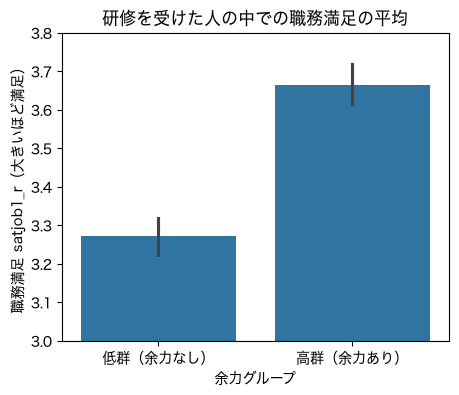

In [343]:
# グラフ用に「グループ名」の列を作る
plot_data = trained.copy()
plot_data["余力グループ"] = np.where(plot_data["wrktime_r"] == 4, "高群（余力あり）", "低群（余力なし）")

plt.figure(figsize=(5, 4))
sns.barplot(data=plot_data, x="余力グループ", y="satjob1_r", errorbar=("ci", 95))
plt.ylim(3.0, 3.8)
plt.ylabel("職務満足 satjob1_r（大きいほど満足）")
plt.title("研修を受けた人の中での職務満足の平均")
plt.show()

### 結果の見方

設計サマリーの実データ結果（高群 3.663／407人、低群 3.271／660人、差 +0.392、t = 10.35、p = 6.6e-24、d = 0.64）が再現できていれば成功。

p値は 0.05 をはるかに下回っているので、
**「研修を受けた人の中でも、余力がある人のほうが職務満足が高い」**と統計的に言える。
効果量 d = 0.64 なので、差の大きさも中程度以上である。

つまり、研修を受けたかどうかだけで満足度が決まるわけではなく、
**「研修を受けても余力がないと満足度は上がらない」**という仮説が支持される。

## 発展（任意）1：同じ手順を「支援」「機会」でも試す

手順2で使う変数を差し替えるだけで、まったく同じやり方が3パターンに使える。
毎回同じコードを書くのは大変なので、一連の処理を**関数**にまとめておく。

- 余力 `wrktime_r`：仕事を終わらせる時間が十分にある
- 支援 `suphelp_r`：上司は仕事を進めるうえで助けになってくれる
- 機会 `promteok_r`：昇進の見込みがある

In [344]:
def run_ttest(factor, outcome="satjob1_r"):
    """研修を受けた人の中を factor で高群／低群に分け、outcome の平均をWelchのt検定で比べる。

    outcome は既定で満足度。最後の頑健性チェックでは "prodctiv_r" を渡して、この関数をそのまま使い回す。
    """
    # その要因にも回答している人だけに絞り、さらに研修あり（train = 1）に限定する
    data = work.dropna(subset=["train", outcome, factor])
    data = data[data["train"] == 1]

    high = data[data[factor] == 4][outcome]   # 最上位＝高群
    low = data[data[factor] < 4][outcome]     # それ以外＝低群

    t, p = stats.ttest_ind(high, low, equal_var=False)
    sd = np.sqrt((high.var(ddof=1) + low.var(ddof=1)) / 2)
    d = (high.mean() - low.mean()) / sd

    # 結果を1行分の辞書にして返す
    return {
        "要因": factor,
        "高群 平均": round(high.mean(), 3),
        "高群 n": len(high),
        "低群 平均": round(low.mean(), 3),
        "低群 n": len(low),
        "差": round(high.mean() - low.mean(), 3),
        "t値": round(t, 2),
        "p値": f"{p:.1e}",
        "効果量 d": round(d, 2),
    }


# 3つの要因それぞれで実行し、表にまとめる
results = [run_ttest(f) for f in ["wrktime_r", "suphelp_r", "promteok_r"]]
results_table = pd.DataFrame(results)
results_table

,要因,高群 平均,高群 n,低群 平均,低群 n,差,t値,p値,効果量 d
0,wrktime_r,3.663,407,3.271,660,0.392,10.35,6.6e-24,0.64
1,suphelp_r,3.637,567,3.178,493,0.458,11.77,6.6e-30,0.73
2,promteok_r,3.694,252,3.335,812,0.359,8.67,5.7e-17,0.59


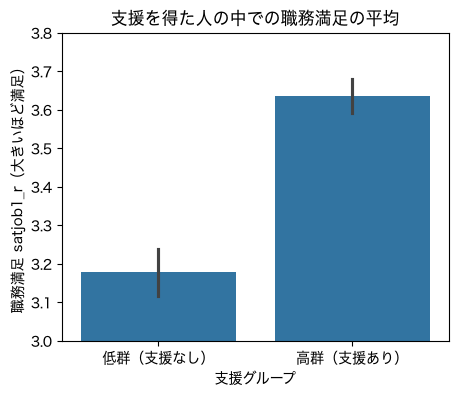

In [345]:
# グラフ用に「グループ名」の列を作る
plot_data = trained.copy()
plot_data["支援グループ"] = np.where(plot_data["suphelp_r"] == 4, "高群（支援あり）", "低群（支援なし）")

plt.figure(figsize=(5, 4))
sns.barplot(data=plot_data, x="支援グループ", y="satjob1_r", errorbar=("ci", 95))
plt.ylim(3.0, 3.8)
plt.ylabel("職務満足 satjob1_r（大きいほど満足）")
plt.title("支援を得た人の中での職務満足の平均")
plt.show()

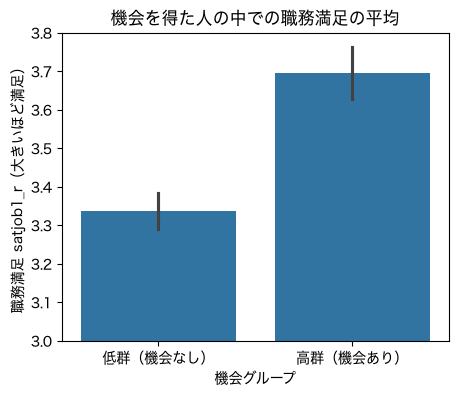

In [346]:
# グラフ用に「グループ名」の列を作る
plot_data = trained.copy()
plot_data["機会グループ"] = np.where(plot_data["promteok_r"] == 4, "高群（機会あり）", "低群（機会なし）")

plt.figure(figsize=(5, 4))
sns.barplot(data=plot_data, x="機会グループ", y="satjob1_r", errorbar=("ci", 95))
plt.ylim(3.0, 3.8)
plt.ylabel("職務満足 satjob1_r（大きいほど満足）")
plt.title("機会を得た人の中での職務満足の平均")
plt.show()

## 発展（任意）2：研修そのものの効果と比べる

「研修だけでは足りない」という中心仮説をいちばん直感的に示すには、
**研修そのものの効果**（研修あり vs 研修なし）を同じ物差しで測って並べるとよい。

ここでは絞り込みをせず、分析対象者全体を `train` の 1／0 で2グループに分ける。

In [347]:
# 研修あり／なしで満足度を比べる
yes_train = analysis[analysis["train"] == 1]["satjob1_r"]
no_train = analysis[analysis["train"] == 0]["satjob1_r"]

t, p = stats.ttest_ind(yes_train, no_train, equal_var=False)
sd = np.sqrt((yes_train.var(ddof=1) + no_train.var(ddof=1)) / 2)
d = (yes_train.mean() - no_train.mean()) / sd

print("=== 研修そのものの効果 ===")
print(f"研修あり 平均: {yes_train.mean():.3f} (n = {len(yes_train)})")
print(f"研修なし 平均: {no_train.mean():.3f} (n = {len(no_train)})")
print(f"差          : {yes_train.mean() - no_train.mean():+.3f}")
print(f"t値         : {t:.2f}")
print(f"p値         : {p:.2e}")
print(f"効果量 d    : {d:.2f}")

=== 研修そのものの効果 ===
研修あり 平均: 3.421 (n = 1067)
研修なし 平均: 3.250 (n = 892)
差          : +0.171
t値         : 5.19
p値         : 2.35e-07
効果量 d    : 0.24


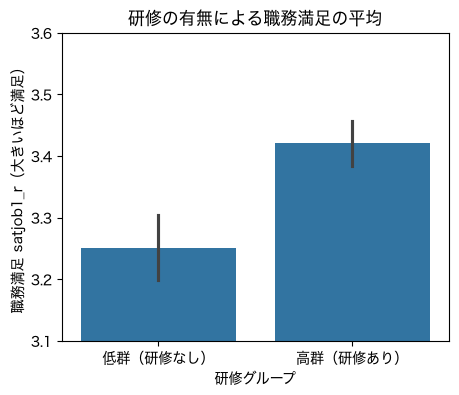

In [348]:
# グラフ用に「グループ名」の列を作る
plot_data = analysis.copy()
plot_data["研修グループ"] = np.where(plot_data["train"] == 1, "高群（研修あり）", "低群（研修なし）")

plt.figure(figsize=(5, 4))
sns.barplot(data=plot_data, x="研修グループ", y="satjob1_r", order=["低群（研修なし）", "高群（研修あり）"], errorbar=("ci", 95))
plt.ylim(3.1, 3.6)
plt.ylabel("職務満足 satjob1_r（大きいほど満足）")
plt.title("研修の有無による職務満足の平均")
plt.show()

## ①のまとめ

| 比べたもの | 高群 平均（n） | 低群 平均（n） | 差 | 効果量 d |
| --- | --- | --- | --- | --- |
| 余力 `wrktime_r`（研修ありの中で） | 3.663（407） | 3.271（660） | +0.392 | 0.64 |
| 支援 `suphelp_r`（研修ありの中で） | 3.637（567） | 3.178（493） | +0.458 | 0.73 |
| 機会 `promteok_r`（研修ありの中で） | 3.694（252） | 3.335（812） | +0.359 | 0.59 |
| **研修そのもの** `train`（対象者全体） | 3.421（1,067） | 3.250（892） | +0.171 | **0.24** |

**読み取り**：研修を受けたかどうかによる満足度の差（d = 0.24、小程度）は、
研修を受けた人の中の余力・支援・機会による差（d = 0.59〜0.73、中程度以上）の**半分以下**しかない。

→ 中心仮説「研修（能力への投資）を増やすだけでは、余力・支援・機会が不足している働き手の状態は改善しない」を支持する結果である。

**注意点**

- この分析はウェイトを使わない単純な平均の比較で、年齢・勤続年数・所得などの違いも統制していない。
- 満足度もQWL項目も本人の主観回答なので、「満足している人ほど職場を良く評価しやすい」という共通方法バイアスの可能性が残る。
- そのため、①はあくまで入口の確認であり、②以降（重回帰・ロジスティック回帰）で改めて検証する。

---

# ② 機械学習の回帰分析：重回帰分析（1種類のみ）

**目的**：4つのボトルネック代表変数のうち、職務満足にもっとも影響しているのはどれかを、1回の分析でまとめて比較する。

**手法**：重回帰分析（Multiple Linear Regression）のみを使う。比較モデルは作らない。

| 役割 | 変数 | 意味 |
| --- | --- | --- |
| **目的変数** | `satjob1_r` | 職務満足（4＝とても満足） |
| 説明変数：能力 | `train` | 研修を受けた（1）／受けていない（0） |
| 説明変数：余力 | `wrktime_r` | 仕事を終わらせる時間がある（4＝とてもそう思う） |
| 説明変数：支援 | `suphelp_r` | 上司が助けてくれる（4＝とてもそう思う） |
| 説明変数：機会 | `promteok_r` | 昇進の見込みがある（4＝とてもそう思う） |

## ①との違い：なぜ重回帰なのか

①のt検定は「余力だけ」「支援だけ」と**1つずつ別々に**比べる方法だった。
しかしこの3つは互いに相関しているので（例：上司が助けてくれる職場は時間の余裕もありがち）、
1つずつ見ると**他の変数の影響が混ざったまま**の数字になってしまう。

重回帰は4つを**同時にモデルへ入れる**ことで、「他の3つを一定に保ったとき、この変数だけを動かすと満足度がどれだけ変わるか」
という**正味の効果**を取り出せる。これが「どれが一番効いているか」を比べたいときに重回帰を使う理由である。

## 手順1：使う変数を決めて、データを準備する

回帰分析は「使う変数がすべて揃っている人」しか計算に使えない。
1つでも欠けている人は自動的に除外されるため、あらかじめ `dropna()` で明示的に落として人数を確認しておく。

→ 5変数が揃うのは **1,930人**。①（3変数で1,959人）より少し減るのは、支援・機会の設問にも答えている必要があるため。

In [349]:
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler

# 目的変数（説明されるもの）と説明変数（説明するもの）を決める
y_col = "satjob1_r"                                          # 職務満足
x_cols = ["train", "wrktime_r", "suphelp_r", "promteok_r"]   # 能力・余力・支援・機会

# 5つの変数がすべて揃っている人だけを残す（1つでも欠けていると回帰に使えない）
reg_data = work.dropna(subset=[y_col] + x_cols)

# scikit-learn では説明変数を X、目的変数を y と置くのが慣例
X = reg_data[x_cols]
y = reg_data[y_col]

print("分析に使う人数:", len(reg_data), "人")
print("X の形（行数, 列数）:", X.shape)
print()
print("使う変数の要約:")
print(reg_data[[y_col] + x_cols].describe().round(3).to_string())

分析に使う人数: 1930 人
X の形（行数, 列数）: (1930, 4)

使う変数の要約:
       satjob1_r     train  wrktime_r  suphelp_r  promteok_r
count   1930.000  1930.000   1930.000   1930.000    1930.000
mean       3.343     0.547      3.192      3.323       2.667
std        0.720     0.498      0.827      0.811       0.960
min        1.000     0.000      1.000      1.000       1.000
25%        3.000     0.000      3.000      3.000       2.000
50%        3.000     1.000      3.000      4.000       3.000
75%        4.000     1.000      4.000      4.000       3.000
max        4.000     1.000      4.000      4.000       4.000


### 削除してよかったのか：感度分析で確かめる

`dropna()` で 2,928人 → 1,930人 と、998人が分析から外れた。
「この削除のせいで結論が変わっていないか」は、実際にモデルを走らせて比べれば確認できる。

欠測の大半は `train` に由来するので、**`train` を外せば n が増える**。
そこで次の3つを比べる。

1. 4変数（現行）：n = 1,930
2. `train` を抜いた3変数：n = 2,770 ← 840人ぶん増える
3. `train` を抜いた3変数を、**1,930人の同じ標本で**：n = 1,930

2と3を比べれば「標本が増えたことの影響」、1と3を比べれば「`train` を入れたことの影響」が分離できる。
ここで係数の順位や大きさが動かなければ、削除によるバイアスは実質的に生じていないと言える。

ついでに、初心者向けの記事でよく紹介される**平均値補完**を試すとどうなるかも見ておく。


In [350]:
def fit_standardized(cols, data):
    """指定した説明変数で標準化重回帰を走らせ、n・R²・標準化係数を返す"""
    d = data.dropna(subset=[y_col] + cols)
    Xs = StandardScaler().fit_transform(d[cols])
    ys = StandardScaler().fit_transform(d[y_col].values.reshape(-1, 1)).ravel()
    m = LinearRegression().fit(Xs, ys)
    return len(d), m.score(Xs, ys), dict(zip(cols, m.coef_.round(3)))


three = ["wrktime_r", "suphelp_r", "promteok_r"]          # train を抜いた3変数

n1, r1, b1 = fit_standardized(x_cols, work)               # 1. 4変数（現行）
n2, r2, b2 = fit_standardized(three, work)                # 2. 3変数・n を増やす
n3, r3, b3 = fit_standardized(three, reg_data)            # 3. 3変数・同じ1,930人

print(f"1. 4変数（現行）      n={n1}  R²={r1:.3f}  {b1}")
print(f"2. train抜き・全員    n={n2}  R²={r2:.3f}  {b2}")
print(f"3. train抜き・同一標本 n={n3}  R²={r3:.3f}  {b3}")

# 参考：train の欠測を平均値で埋めた場合（推奨しない方法）
filled = work.dropna(subset=[y_col] + three).copy()
filled["train_imp"] = filled["train"].fillna(filled["train"].mean())
n4, r4, b4 = fit_standardized(["train_imp"] + three, filled)
print(f"\n参考：平均値補完      n={n4}  R²={r4:.3f}  {b4}")
print("→ 能力の係数が 0.080 から縮む。全員に同じ値を入れるとばらつきが人工的に小さくなり、")
print("  係数が0方向に引っ張られるため。平均値補完は結果を歪めるので使わない。")


1. 4変数（現行）      n=1930  R²=0.251  {'train': np.float64(0.08), 'wrktime_r': np.float64(0.21), 'suphelp_r': np.float64(0.289), 'promteok_r': np.float64(0.174)}
2. train抜き・全員    n=2770  R²=0.246  {'wrktime_r': np.float64(0.195), 'suphelp_r': np.float64(0.297), 'promteok_r': np.float64(0.186)}
3. train抜き・同一標本 n=1930  R²=0.245  {'wrktime_r': np.float64(0.201), 'suphelp_r': np.float64(0.296), 'promteok_r': np.float64(0.185)}

参考：平均値補完      n=2770  R²=0.250  {'train_imp': np.float64(0.064), 'wrktime_r': np.float64(0.201), 'suphelp_r': np.float64(0.292), 'promteok_r': np.float64(0.179)}
→ 能力の係数が 0.080 から縮む。全員に同じ値を入れるとばらつきが人工的に小さくなり、
  係数が0方向に引っ張られるため。平均値補完は結果を歪めるので使わない。


**読み取り**：`train` を外して n を 2,770人 まで増やしても、
**支援 > 余力 > 機会という順位も係数の大きさもほとんど変わらない**（2と3を比較）。
削除によるバイアスは実質的に生じていないと確認できた。

一方、平均値補完をすると能力の係数だけが縮む。埋めた人全員が同じ値になるため
変数のばらつきが人工的に小さくなり、**効果が実際より弱く見えてしまう**。
「とりあえず平均で埋める」が危険だと分かる例である。


### 走らせる前のチェック：説明変数どうしが似すぎていないか

重回帰では、説明変数どうしがそっくりだと「どちらが効いているのか」を機械が判別できなくなり、
係数が不安定になる。これを**多重共線性**という。

確認方法は2つある。

- **相関係数**：説明変数どうしの相関。目安として 0.8 を超えると危険
- **VIF（分散拡大要因）**：その変数が他の変数でどれだけ説明できてしまうかの指標。
  1に近いほど良く、2未満なら気にしなくてよい。10を超えると要注意

VIF は専用ライブラリがなくても、`LinearRegression` だけで計算できる。
「ある説明変数を、残りの説明変数で予測する回帰」を走らせて決定係数 R² を出し、`VIF = 1 ÷ (1 − R²)` とすればよい。
他の変数でぴったり予測できてしまう（R² が1に近い）ほど VIF が大きくなる、という素直な仕組みである。

今回は4つとも VIF が 1.2 以下に収まるはずなので、そのまま4変数を同時に投入してよい。

In [351]:
# 説明変数どうしの相関
print("説明変数どうしの相関:")
print(X.corr().round(3).to_string())

# VIF：ある説明変数を「残りの説明変数」で予測し、VIF = 1 / (1 - R²) で求める
vif_rows = []
for col in x_cols:
    others = [c for c in x_cols if c != col]        # その変数以外の3つ
    model_vif = LinearRegression()
    model_vif.fit(X[others], X[col])                # 他の3つで、その変数を予測してみる
    r2_others = model_vif.score(X[others], X[col])  # どれだけ言い当てられたか
    vif_rows.append({"変数": col, "R²": round(r2_others, 3), "VIF": round(1 / (1 - r2_others), 2)})

print("\nVIF（多重共線性のチェック）:")
print(pd.DataFrame(vif_rows).to_string(index=False))


説明変数どうしの相関:
            train  wrktime_r  suphelp_r  promteok_r
train       1.000     -0.053      0.087       0.148
wrktime_r  -0.053      1.000      0.372       0.140
suphelp_r   0.087      0.372      1.000       0.247
promteok_r  0.148      0.140      0.247       1.000

VIF（多重共線性のチェック）:
        変数    R²  VIF
     train 0.034 1.04
 wrktime_r 0.150 1.18
 suphelp_r 0.183 1.22
promteok_r 0.081 1.09


## 手順2：重回帰分析を実行する（まずは元の単位のまま）

scikit-learn の `LinearRegression`（線形回帰）を使う。使い方は3行だけで、
機械学習ライブラリはどのモデルでもこの形なので、覚えると他の手法にも流用できる。

```python
model = LinearRegression()   # ① 箱を用意する
model.fit(X, y)              # ② データを学習させる
model.score(X, y)            # ③ 当てはまりを確認する
```

得られた結果は次の場所に入っている。

| 属性・メソッド | 意味 |
| --- | --- |
| `model.coef_` | 各説明変数の係数（1増えたとき満足度がどれだけ増えるか） |
| `model.intercept_` | 切片（すべての説明変数が0のときの予測値） |
| `model.score(X, y)` | 決定係数 R²（目的変数のばらつきを何割説明できたか） |

**scikit-learn の注意点**：予測を目的としたライブラリなので、**p値を出す機能がない**。
統計的に「その効果は偶然ではない」と言うには p値 が要るので、`calc_pvalues()` という関数にまとめて計算する。
中身は行列計算なので、はじめのうちは**道具として使うだけでよい**。

表示するのは**係数と p値 の2つだけ**にする。関数は標準誤差や t値 も返すが、
これらは p値 を求める途中で出てくる値であって、それ自体を読んで判断するものではないためである。

なお `coef_` は**元の単位のまま**なので、この数字どうしを並べて順位をつけることはできない（理由は手順3で説明する）。


In [352]:
# ① 箱を用意して ② 学習させる
model = LinearRegression()
model.fit(X, y)

# ③ 当てはまりを確認する
print(f"人数 n      : {len(X)}")
print(f"決定係数 R² : {model.score(X, y):.4f}")
print(f"切片        : {model.intercept_:.4f}")


def calc_pvalues(model, X, y):
    """回帰係数の p値 を計算する。

    scikit-learn は p値 を出してくれないので自前で求める。
    中身は行列計算なので、はじめのうちは「そういう道具」と思って使ってよい。
    """
    n, k = X.shape
    resid = y - model.predict(X)                    # 実測値 − 予測値
    mse = (resid ** 2).sum() / (n - k - 1)          # 残差の分散
    X1 = np.column_stack([np.ones(n), X])           # 切片ぶんの列（すべて1）を足す
    se = np.sqrt(mse * np.diag(np.linalg.inv(X1.T @ X1)))   # 各係数の標準誤差
    coefs = np.r_[model.intercept_, model.coef_]
    t = coefs / se                                  # t値 = 係数 ÷ 標準誤差
    p = stats.t.sf(np.abs(t), n - k - 1) * 2        # 両側検定の p値
    return coefs, se, t, p


# 表に出すのは「係数」と「p値」だけ。標準誤差と t値 は p値 を求める途中の値なので受け取るだけにする
coefs, se, t_values, p_values = calc_pvalues(model, X, y)

# [1:] で先頭の切片を除き、説明変数4つだけの表にする
coef_table = pd.DataFrame({
    "変数": x_cols,
    "係数": coefs[1:].round(4),
    "p値": [f"{p:.3g}" for p in p_values[1:]],
})
print("\n回帰係数（元の単位）:")
print(coef_table.to_string(index=False))


人数 n      : 1930
決定係数 R² : 0.2510
切片        : 1.4967

回帰係数（元の単位）:
        変数     係数       p値
     train 0.1158 6.85e-05
 wrktime_r 0.1827 3.18e-22
 suphelp_r 0.2563 2.23e-38
promteok_r 0.1305 5.25e-17


R² 0.8以上が求められるのは、検量線・機械の較正・工学的な測定など、結果が入力でほぼ決まる世界である。バネの伸びは荷重でほぼ決まるので、R² が 0.8 に届かなければ測定か式のどちらかがおかしい、と判断できる。

一方、人間の満足度は本人の性格・給料・仕事内容・家庭の事情・その日の体調・上司との相性など、無数の要因の合成である。社会科学では R² = 0.1〜0.3 が普通の水準で、R² = 0.251 は、社会調査データでは中〜大の効果量にあたる。属性情報のみでは 0.041 にとどまることと比較すると、職場環境要因の説明力は明確である。

なお本分析の目的は個人の満足度予測ではなく要因間の比較であり、係数の推定精度（p < 0.001）が確保されている点が重要である。

## 手順3：標準化して「どれが一番効いているか」を比べる

上の `係数` をそのまま並べて順位をつけては**いけない**。理由は、変数によって「1」の意味が違うからである。

- `train` の1 ＝ 研修を受けた／受けていないという**全部か無かの差**
- `suphelp_r` の1 ＝ 4段階のうち**1段階分**の差

物差しの目盛りが違うものを並べて「こちらが大きい」とは言えない。
そこで**すべての変数を「平均0・標準偏差1」に変換してから**同じ回帰を走らせる。
こうして得た係数を**標準化係数（β）**といい、「その変数が1標準偏差ぶん動いたとき、
満足度が何標準偏差ぶん動くか」を表すので、**変数どうしを対等に比較できる**。

scikit-learn にはこの変換専用の `StandardScaler` がある。使い方は `LinearRegression` と同じ2段構えで、
`fit_transform(データ)` と書けば変換後の値が返ってくる。

なお `y`（目的変数）は1列だけの Series なので、`StandardScaler` に渡すときは
`.values.reshape(-1, 1)` で「1列の表」の形にしてやる必要がある（scikit-learn は表形式を前提にしているため）。
戻ってきた結果は `.ravel()` で1列に戻す。

In [353]:
# --- 説明変数 X を標準化する ---
scaler_X = StandardScaler()             # ① 変換器を用意する
X_std = scaler_X.fit_transform(X)       # ② 平均0・標準偏差1に変換する

# --- 目的変数 y を標準化する ---
# StandardScaler は「表（2次元）」を前提にしている。
# 一方 y は1列だけの Series（1次元）なので、形をそろえる手順が1つ増える。
y_table = y.values.reshape(-1, 1)       # ① 1次元 → 縦1列の表にする
scaler_y = StandardScaler()             # ② 変換器を用意する
y_std_table = scaler_y.fit_transform(y_table)   # ③ 変換する（結果も縦1列の表）
y_std = y_std_table.ravel()             # ④ 表 → 1次元に戻す

# 形が意図どおりか確認しておく（(行数, 列数) が表示される）
print("X       :", X.shape, "→ X_std   :", X_std.shape)
print("y       :", y.shape, "→ y_table :", y_table.shape, "→ y_std:", y_std.shape)

# 変換したデータで、まったく同じ重回帰をもう一度走らせる
model_std = LinearRegression()
model_std.fit(X_std, y_std)

# 結果を見やすい表にまとめる（p値は標準化しても変わらないので手順2の値を使う）
result = pd.DataFrame({
    "ボトルネック": ["能力", "余力", "支援", "機会"],
    "変数": x_cols,
    "標準化係数 β": model_std.coef_.round(3),
    "p値": [f"{p:.3g}" for p in p_values[1:]],   # 先頭は切片なので1番目以降
})

# 影響が大きい順に並べ替えて、1位から順位を振る
result = result.sort_values("標準化係数 β", ascending=False).reset_index(drop=True)
result.index = result.index + 1
result.index.name = "順位"
result


X       : (1930, 4) → X_std   : (1930, 4)
y       : (1930,) → y_table : (1930, 1) → y_std: (1930,)


,ボトルネック,変数,標準化係数 β,p値
順位,,,,
1,支援,suphelp_r,0.289,2.23e-38
2,余力,wrktime_r,0.210,3.18e-22
3,機会,promteok_r,0.174,5.25e-17
4,能力,train,0.080,6.85e-05


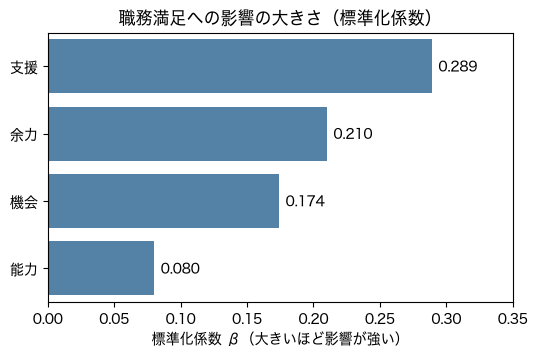

In [354]:
# 標準化係数を横棒グラフにする（長いほど影響が大きい）
plt.figure(figsize=(6, 3.5))
sns.barplot(data=result, x="標準化係数 β", y="ボトルネック", color="steelblue")
plt.title("職務満足への影響の大きさ（標準化係数）")
plt.xlabel("標準化係数 β（大きいほど影響が強い）")
plt.ylabel("")

# 棒の右端に数値を書き込む
for i, v in enumerate(result["標準化係数 β"]):
    plt.text(v + 0.005, i, f"{v:.3f}", va="center")

plt.xlim(0, 0.35)
plt.show()

### ②の結果の読み方

**1. モデル全体**：`決定係数 R² = 0.251` は「職務満足のばらつきのうち25.1%を、この4変数で説明できた」という意味。
人の気持ちを扱うアンケート分析としては十分に高い部類である（残りの74.9%は、給料・仕事内容・家庭の事情など、
モデルに入れていない要因や偶然によるもの）。4変数のp値がすべて 0.05 を大きく下回っているので、
「たまたまこう見えているだけ」という可能性は否定できる。

**2. 順位**：標準化係数を大きい順に並べると **支援（0.289）> 余力（0.210）> 機会（0.174）> 能力（0.080）** となり、
**支援が能力の約3.6倍**の影響を持つ。能力（研修）は有意ではあるが、4つの中では最下位である。

**3. ①との関係**：①のt検定では「研修を受けた人の中で」余力・支援・機会を1つずつ比べた。
②では4つを同時にモデルへ入れているので、**互いの影響を差し引いたうえでの正味の効果**が分かる。
それでも支援が最大という結論は変わらなかった。

### ②のまとめ

| 順位 | ボトルネック | 変数 | 標準化係数 β |
| --- | --- | --- | --- |
| 1 | 支援 | `suphelp_r` | **0.289** |
| 2 | 余力 | `wrktime_r` | 0.210 |
| 3 | 機会 | `promteok_r` | 0.174 |
| 4 | 能力 | `train` | 0.080 |

**読み取り**：研修（能力）への投資は確かに効くが、効果の大きさでは支援と余力に大きく劣る。
一律の研修拡充より、**上司の助力や時間的余裕の確保を優先するほうが職務満足を高める見込みが大きい**。

**注意点**

- これは相関にもとづく分析であり、因果関係を示すものではない。「上司が助けてくれるから満足度が高い」のか
  「満足している人が上司を好意的に評価している」のかは、このデータからは区別できない。
- 年齢・勤続年数・所得などを統制していない。設計サマリーの中級者向け版では、これらを加えたモデルを扱う。
- ウェイト（`wtssnrps`）を使っていないので、「全米の就業者では〜%」という水準の話には使えない。
  ここで見ているのは**変数どうしの効き方の大小**である。
- 今回は手元のデータ全部を学習に使った（`fit` と `score` に同じ `X` を渡した）。
  「未知の人の満足度を当てる」精度を測りたい場合は、`train_test_split` でデータを分ける必要がある。
  ただし②の目的は予測ではなく**係数の比較**なので、ここではその手順を踏んでいない。
- 次の③では、同じ4変数で「高満足かどうか」を当てる**ロジスティック回帰**（`LogisticRegression`）を行い、
  ②の順位が手法を変えても再現されるかを確かめる。

---

# ③ 機械学習の分類分析：ロジスティック回帰で②の結果を検証する

**目的**：②の重回帰分析と同じ問い（「4つのボトルネック代表変数のうち、職務満足にもっとも影響しているのはどれか」）を、
回帰とは別の切り口である**分類**でも確認し、②の結論が手法を変えても揺らがないかを確かめる。

**手法**：ロジスティック回帰（1種類のみ）を使う。比較モデルは作らない。

| 役割 | 変数 | 意味 |
| --- | --- | --- |
| **目的変数** | `high_sat`（新しく作る） | 高満足（1）／それ以外（0） |
| 説明変数 | `train` / `wrktime_r` / `suphelp_r` / `promteok_r` | ②とまったく同じ4つ |

## 回帰と分類は何が違うのか

- **回帰**（②）：満足度を **1〜4の数値そのもの**として予測する
- **分類**（③）：満足度を **「高満足かどうか」の2択**に丸めて、どちらに入るかを予測する

同じデータでも、目的変数の作り方とモデルの形が変わる。それでも**同じ順位が出れば結論は頑健**だと言える。
逆に順位が入れ替わるなら、「たまたま重回帰でそう見えただけ」という疑いが残る。
③はこの**答え合わせ**のために行う。

## 手順1：目的変数を2値にする

`satjob1_r` は 4（Very satisfied）〜 1（Not at all satisfied）の4段階。
これを **4なら1、それ以外は0** の変数 `high_sat` に変換する。

区切りをここに置く理由は、高満足が **46.5%** とほぼ半々になり、分類として扱いやすいためである。
（もし「Somewhat satisfied」まで満足に含めると9割が満足側になり、
ほぼ全員を「満足」と予測するだけのモデルになってしまう。）

なお `.astype(int)` は True/False を 1/0 に変換する書き方で、ダミー変数を作るときの定番である。

In [355]:
# ②とまったく同じ人たち（5変数が揃っている1,930人）を使う
logit_data = reg_data.copy()

# 目的変数を作る：satjob1_r が 4（= Very satisfied）なら 1、それ以外は 0
logit_data["high_sat"] = (logit_data["satjob1_r"] == 4).astype(int)

print("元の職務満足（satjob1_r）の分布:")
print(logit_data["satjob1_r"].value_counts().sort_index().to_string())
print()
print("2値化した high_sat の分布:")
print(logit_data["high_sat"].value_counts().sort_index().to_string())
print()
print(f"高満足の割合: {logit_data['high_sat'].mean():.3f}")

元の職務満足（satjob1_r）の分布:
satjob1_r
1.0     46
2.0    144
3.0    842
4.0    898

2値化した high_sat の分布:
high_sat
0    1032
1     898

高満足の割合: 0.465


## 手順2：ロジスティック回帰を実行する

使い方は②の `LinearRegression` とまったく同じ4段構えである。

```python
logit_model = LogisticRegression()          # ① 箱を用意する
logit_model.fit(X, y)                       # ② 学習させる
logit_model.score(X, y)                     # ③ 当てはまりを確認する
logit_model.predict(X)                      # ④ 予測する
```

②との違いは `score()` が返すものだけである。

| | `score()` が返す値 |
| --- | --- |
| ② `LinearRegression` | 決定係数 R²（数値をどれだけ言い当てたか） |
| ③ `LogisticRegression` | **正答率**（0か1かをどれだけ当てたか） |

`predict()` は 0 か 1 を返す。「高満足になる確率」そのものが欲しいときは `predict_proba()` を使う。

### 係数はオッズ比に直して読む

ロジスティック回帰の係数はそのままでは解釈しづらいので、`exp()`（指数関数）で変換した
**オッズ比**として読むのが慣例である。

- **オッズ**：起こる確率 ÷ 起こらない確率。「高満足になる確率が2/3」なら オッズ = 2
- **オッズ比**：説明変数が1増えたとき、オッズが**何倍**になるか
  - 1より大きい → 高満足になりやすくなる
  - 1ちょうど → 効果なし
  - 1より小さい → 高満足になりにくくなる

なお③では p値 を計算しない。③の目的は「②と順位が一致するか」の確認であり、
**同じ4変数の有意性は②ですでに確かめている**（すべて p < 0.01）ためである。

### `C=1e9` とは何か（正則化の話）

**正則化**とは、機械学習が「学習しすぎる」のを防ぐブレーキのことである。

モデルは手元のデータに合わせようとするあまり、たまたまの偶然まで覚え込んでしまうことがある。
これを**過学習**といい、こうなると手元のデータでは高得点でも、**未知のデータではまるで当たらない**モデルになる。
そこで「係数を大きくしすぎたらペナルティを与える」という制約を課し、係数を0のほうへ引き戻しておく。
これが正則化である。

`C` はそのブレーキの強さを表す設定値で、**向きが逆になっている**点に注意する。

| `C` の値 | ブレーキ | 係数 |
| --- | --- | --- |
| 小さい（0.01 など） | **強く効く** | 0に近づく（小さくなる） |
| 大きい（1e9 など） | **ほとんど効かない** | 本来の値のまま |

scikit-learn の既定値は `C=1.0`。予測モデルを作るときは `C=0.1` のように**小さめにして過学習を防ぐ**のが定石である。

### それなのに、なぜ今回は `C=1e9`（＝ブレーキを外す）のか

**目的が予測ではなく解釈だから**である。

③でやりたいのは「未知の人の満足度を当てる」ことではなく、
**「4つのボトルネックのうちどれが一番効いているか、オッズ比はいくつか」を正しく読み取る**ことだった。

ここで正則化を効かせると、係数が**意図的に0へ縮められる**。つまり本来2.14倍の効果が「1.73倍」と
実際より小さく報告されてしまう。予測精度のためにわざと歪めた数値を、そのまま
「上司の助力は満足度を◯倍にする」と報告してしまうのは誤りである。

実際に `C` を変えるとオッズ比はこう変わる。

| `C` | 能力 | 余力 | 支援 | 機会 | 正答率 |
| --- | --- | --- | --- | --- | --- |
| 0.01（強いブレーキ） | 1.17 | 1.61 | **1.73** | 1.31 | 0.6891 |
| 0.1 | 1.34 | 1.86 | 2.08 | 1.37 | 0.6912 |
| 1.0（既定値） | 1.38 | 1.91 | 2.14 | 1.37 | 0.6912 |
| **1e9（今回）** | **1.38** | **1.91** | **2.14** | **1.37** | 0.6912 |

ブレーキを強くすると支援のオッズ比が 2.14 → 1.73 まで縮む一方で、**正答率はほとんど変わらない**
（0.6912 → 0.6891）。予測性能を犠牲にせずに数値だけが歪むわけで、解釈が目的の分析には不向きだと分かる。

まとめると、使い分けは次のとおり。

| 目的 | `C` の設定 |
| --- | --- |
| 未知のデータを当てたい（予測） | `C=0.1` など小さめ＋`train_test_split` で検証 |
| **係数の大きさを読み取りたい（解釈）** | **`C=1e9` でブレーキを外す** |

`max_iter=1000` は、計算が途中で打ち切られないようにするための保険である
（実際は14回で収束するので、既定の100でも足りる）。


In [356]:
from sklearn.linear_model import LogisticRegression

# 説明変数は②とまったく同じ4つ
X_logit = logit_data[x_cols]
y_logit = logit_data["high_sat"]

# ① 箱を用意する
logit_model = LogisticRegression(C=1e9, max_iter=1000)

# ② 学習させる
logit_model.fit(X_logit, y_logit)

# ③ 当てはまりを確認する（分類なので、返ってくるのは正答率）
print("正答率:", round(logit_model.score(X_logit, y_logit), 4))

# ④ 予測する ― 先頭8人について、入力値と予測結果を並べて確認する
check = X_logit.head(8).astype(int).copy()
check["高満足の確率"] = logit_model.predict_proba(X_logit)[:8, 1].round(3)  # 1になる確率
check["予測"] = logit_model.predict(X_logit)[:8]                          # 0か1の判定
check["実際"] = y_logit.values[:8]                                        # 本当の答え
check["当たり"] = np.where(check["予測"] == check["実際"], "○", "×")
check.index = [f"{i}人目" for i in range(1, 9)]
check


正答率: 0.6912


,train,wrktime_r,suphelp_r,promteok_r,高満足の確率,予測,実際,当たり
1人目,1,2,2,3,0.148,0,0,○
2人目,0,4,4,1,0.530,1,1,○
3人目,0,3,3,2,0.274,0,1,×
4人目,0,1,1,1,0.016,0,0,○
5人目,0,2,2,1,0.063,0,0,○
6人目,0,4,3,2,0.418,0,1,×
7人目,1,3,3,2,0.342,0,0,○
8人目,1,2,2,2,0.113,0,0,○


In [357]:
# 係数を取り出して、オッズ比に直して並べる
coefs_logit = logit_model.coef_[0]          # 4つの係数（[0] が必要なのは、分類器の係数が2次元で返るため）

logit_table = pd.DataFrame({
    "変数": x_cols,
    "係数": coefs_logit.round(4),
    "オッズ比": np.exp(coefs_logit).round(3),   # exp() でオッズ比に変換する
})
print("ロジスティック回帰の結果（元の単位）:")
print(logit_table.to_string(index=False))


ロジスティック回帰の結果（元の単位）:
        変数     係数  オッズ比
     train 0.3218 1.380
 wrktime_r 0.6473 1.910
 suphelp_r 0.7628 2.144
promteok_r 0.3155 1.371


## 手順3：モデルの当てはまりを確認する

分類では R² の代わりに次の指標を見る。

| 指標 | 意味 | 見方 |
| --- | --- | --- |
| **正答率**（accuracy） | 予測が当たった割合 | **基準率と比べる**のが必須 |
| **基準率** | 何も考えず全員を多数派に振り分けたときの正答率 | これを超えないモデルは無意味 |
| **混同行列** | 予測と実際の組み合わせを数えた2×2の表 | どちら側を間違えやすいかが分かる |

今回は「高満足」が46.5%なので、多数派は「高満足でない」側の53.5%。
**正答率が53.5%を超えていなければ、モデルに意味はない**。ここを確認せずに
「正答率69%も当たった」と報告するのは、初心者がやりがちな誤りである。

In [358]:
from sklearn.metrics import confusion_matrix

# ③で見た正答率を、比較対象と並べて評価する
accuracy = logit_model.score(X_logit, y_logit)
base_rate = max(y_logit.mean(), 1 - y_logit.mean())   # 多数派に全員を振り分けたときの正答率

print(f"正答率 : {accuracy:.4f}")
print(f"基準率 : {base_rate:.4f}  ← 全員を多数派に振り分けたときの正答率")
print(f"改善分 : {accuracy - base_rate:+.4f}")

# 混同行列：予測と実際の組み合わせを数えた表
cm = pd.DataFrame(
    confusion_matrix(y_logit, logit_model.predict(X_logit)),
    index=["実際：高満足でない", "実際：高満足"],
    columns=["予測：高満足でない", "予測：高満足"],
)
print("\n混同行列:")
print(cm.to_string())


正答率 : 0.6912
基準率 : 0.5347  ← 全員を多数派に振り分けたときの正答率
改善分 : +0.1565

混同行列:
           予測：高満足でない  予測：高満足
実際：高満足でない        737     295
実際：高満足           301     597


### 混同行列の読み方：外れ方には2種類ある

正答率 69.1% の裏側には、**種類の違う2つの誤り**が隠れている。混同行列の4つのマスはそれぞれこう読む。

```
           予測：高満足でない  予測：高満足
実際：高満足でない        737     295   ← モデルが高く見すぎた
実際：高満足           301     597
                        ↑ モデルが低く見すぎた
```

| マス | 人数 | 何が起きたか |
| --- | --- | --- |
| 737 | 正解 | 高満足でない人を、正しく「高満足でない」と判定 |
| 597 | 正解 | 高満足の人を、正しく「高満足」と判定 |
| **295** | **モデルが高く見すぎた**（偽陽性） | 実際は高満足**でない**のに、「高満足」と判定した |
| **301** | **モデルが低く見すぎた**（偽陰性） | 実際は高満足**なのに**、「高満足でない」と判定した |

正解 737 + 597 = 1,334人 → 1334 ÷ 1930 = **0.6912**（正答率）
外れ 295 + 301 = 596人 → 596 ÷ 1930 = **0.3088**（約3割）

> **用語について**：「過大評価／過小評価」という言い方は、主語が**モデル**なのか**本人**なのかで
> 意味が逆になってしまう。たとえば下の301人は、モデルから見れば「低く見積もった（過小評価）」だが、
> 本人から見れば「環境は普通なのに満足と答えた（過大評価）」とも読める。
> 混乱を避けるため、ここでは主語を**モデル**に固定して「高く見すぎた／低く見すぎた」と表記する。

### それぞれどんな人か

**モデルが高く見すぎた（295人）＝環境の評価は高いが、実際には高満足と答えなかった人**

| | train | wrktime_r | suphelp_r | promteok_r | 確率 | 予測 | 実際 |
| --- | --- | --- | --- | --- | --- | --- | --- |
| 23人目 | 1 | 4 | 4 | 4 | 0.800 | 1 | 0 |

研修も受け、余力・支援・機会がすべて最高評価。モデルは「80%の確率で高満足だろう」と判断したが、
実際の回答は Somewhat satisfied 以下だった。給料や仕事内容など、**モデルに入れていない要因**で
満足していないのだと考えられる。

**モデルが低く見すぎた（301人）＝環境の評価は平均的だが、実際には高満足と答えた人**

| | train | wrktime_r | suphelp_r | promteok_r | 確率 | 予測 | 実際 |
| --- | --- | --- | --- | --- | --- | --- | --- |
| 3人目 | 0 | 3 | 3 | 2 | 0.274 | 0 | 1 |

各項目が3程度（そこそこ）で確率27%と判定されたが、実際は Very satisfied。こちらも4変数の外に理由がある。

### ここから分かる2つのこと

**1. モデルは特定の方向に偏っていない**

高く見すぎた295人と低く見すぎた301人がほぼ**同数**である。どちらか一方が極端に多い場合は、
しきい値0.5が不適切か、データが偏っている可能性を疑う必要がある。今回はバランスが取れている。

**2. 職務満足は4つのボトルネックだけでは決まらない**

両方向に外れが出ているという事実は、**説明しきれていない要因が残っている**ことの表れである。
②で見た R² = 0.251（説明できたのは25%）と同じことを、分類の側から見ていることになる。

### 補足：どちらの誤りが痛手かは「1が何を表すか」で決まる

2つの誤りは対等ではない。ただし**どちらが重いかは、目的変数の1をどちらに割り当てたかで入れ替わる**。
ここは混同しやすいので、今回のモデルに即して確認しておく。

本モデルは **1＝高満足（望ましい状態）** である。したがって：

| 誤り | 実務上の意味 | 痛手の度合い |
| --- | --- | --- |
| 低く見すぎた（301人） | 満足している人を「不満そう」と判定する。必要のない支援を差し向けるだけ | **小さい**（無駄はあるが害はない） |
| 高く見すぎた（295人） | 不満な人を「大丈夫そう」と判定する。**支援が必要な人を取りこぼす** | **大きい** |

つまり本モデルで警戒すべきは、**高く見すぎた295人**のほうである。

一方、たとえば「離職しそうな人を見つけて面談する」というモデルでは **1＝離職（望ましくない事象）** になる。
この場合は逆で、本当に辞める人を見落とす**偽陰性のほうが痛手**になる。

痛手の大きい側を減らしたいときは、しきい値を0.5から動かして調整する。
本モデルで「高く見すぎ」を減らしたいなら、しきい値を0.5より**上げて**「高満足」と判定しにくくすればよい。

今回は予測が目的ではないのでしきい値はそのままだが、混同行列を見る意義はここにある。
**「正答率69%」という1つの数字では、この非対称性が見えない。**


## 手順4：標準化して②と順位を比べる

②のときと同じ理由で、**オッズ比をそのまま並べて順位をつけることはできない**。
`train` は0/1のダミー変数なので「1の変化」＝研修の有無という全部か無かの差だが、
`suphelp_r` の「1の変化」は4段階のうち1段階分でしかない。上の表で `train`（1.38）と `promteok_r`（1.37）が
ほぼ並んで見えるのは、この物差しの違いによる見かけの現象である。

そこで説明変数を標準化してから同じロジスティック回帰を走らせ、**標準化オッズ比**を出す。
これは「その変数が1標準偏差ぶん良くなると、高満足になるオッズが何倍になるか」を表すので、
4つを対等に比較できる。

そのうえで、②の標準化係数 β と並べて**順位が一致するか**を確認する。
一致すれば「②の結論は手法を変えても揺らがない」と言える。これが③の最大の目的である。

In [359]:
# 説明変数を「平均0・標準偏差1」にそろえてから、同じロジスティック回帰を走らせる
X_logit_std = StandardScaler().fit_transform(X_logit)

logit_std = LogisticRegression(C=1e9, max_iter=1000)
logit_std.fit(X_logit_std, y_logit)

logit_result = pd.DataFrame({
    "ボトルネック": ["能力", "余力", "支援", "機会"],
    "変数": x_cols,
    "標準化オッズ比": np.exp(logit_std.coef_[0]).round(3),
})

# 影響が大きい順に並べ替えて、1位から順位を振る
logit_result = logit_result.sort_values("標準化オッズ比", ascending=False).reset_index(drop=True)
logit_result.index = logit_result.index + 1
logit_result.index.name = "順位"
logit_result


,ボトルネック,変数,標準化オッズ比
順位,,,
1,支援,suphelp_r,1.856
2,余力,wrktime_r,1.708
3,機会,promteok_r,1.354
4,能力,train,1.174


②（重回帰）と③（ロジスティック回帰）の比較:
ボトルネック         変数  標準化係数 β  標準化オッズ比  ②の順位  ③の順位 一致
    支援  suphelp_r    0.289    1.856     1     1  ○
    余力  wrktime_r    0.210    1.708     2     2  ○
    機会 promteok_r    0.174    1.354     3     3  ○
    能力      train    0.080    1.174     4     4  ○


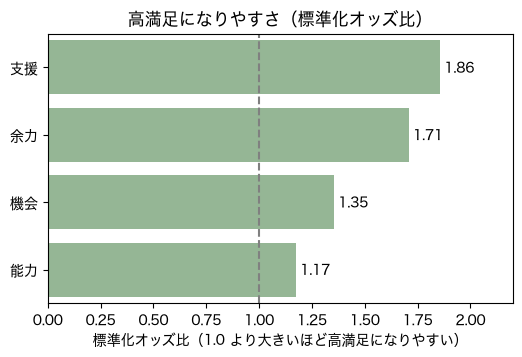

In [360]:
# ②の標準化係数（result）と ③の標準化オッズ比を横に並べて、順位が一致するか確かめる
compare = pd.merge(
    result[["ボトルネック", "変数", "標準化係数 β"]],      # ②の結果
    logit_result[["変数", "標準化オッズ比"]],              # ③の結果
    on="変数",
)
compare["②の順位"] = compare["標準化係数 β"].rank(ascending=False).astype(int)
compare["③の順位"] = compare["標準化オッズ比"].rank(ascending=False).astype(int)
compare["一致"] = np.where(compare["②の順位"] == compare["③の順位"], "○", "×")

print("②（重回帰）と③（ロジスティック回帰）の比較:")
print(compare.to_string(index=False))

# グラフ：③の標準化オッズ比（1.0 が「効果なし」の基準線）
plt.figure(figsize=(6, 3.5))
sns.barplot(data=logit_result, x="標準化オッズ比", y="ボトルネック", color="darkseagreen")
plt.axvline(1.0, color="gray", linestyle="--")          # 1.0 = 効果なし
plt.title("高満足になりやすさ（標準化オッズ比）")
plt.xlabel("標準化オッズ比（1.0 より大きいほど高満足になりやすい）")
plt.ylabel("")
for i, v in enumerate(logit_result["標準化オッズ比"]):
    plt.text(v + 0.02, i, f"{v:.2f}", va="center")
plt.xlim(0, 2.2)
plt.show()


### ③の結果の読み方

**1. 当てずっぽうより当たっているか**：正答率 69.1% に対し、基準率は 53.5%
（＝何も考えず全員を多数派の「高満足ではない」側に振り分けたときの正答率）。
**15.6ポイント上回った**ので、4つのボトルネックには「高満足かどうか」を当てる力が確かにある。

**2. 順位が②と一致したか**：標準化オッズ比の順位は **支援 > 余力 > 機会 > 能力** で、②の標準化係数の順位と**完全に一致**した。
回帰（連続量の満足度を予測）と分類（高満足かどうかを判別）という**別々の切り口で同じ結論**が出たので、
「支援が最大のボトルネックである」という②の結論は、手法を変えても揺らがない頑健な結果だと確認できた。

**3. 効果の大きさ**：上司の助力が1段階上がると、高満足になるオッズが **2.14倍**になる。
研修を受けた場合は 1.38倍にとどまる。

### ③のまとめ

| 順位 | ボトルネック | ②の標準化係数 β | ③の標準化オッズ比 | 一致 |
| --- | --- | --- | --- | --- |
| 1 | 支援 `suphelp_r` | **0.289** | **1.86** | ✓ |
| 2 | 余力 `wrktime_r` | 0.210 | 1.71 | ✓ |
| 3 | 機会 `promteok_r` | 0.174 | 1.35 | ✓ |
| 4 | 能力 `train` | 0.080 | 1.17 | ✓ |

**読み取り**：②（重回帰）と③（ロジスティック回帰）はモデルの形も目的変数の作り方も違うのに、
4つのボトルネックの順位はぴったり同じだった。**「支援 → 余力 → 機会 → 能力」という優先順位は、
分析手法の選び方に左右されない**と報告してよい。

**注意点**

- ②と同じく、これは相関にもとづく分析であり因果関係は示せない。
- 学習に使ったデータでそのまま正答率を測っているので、この 69.1% は**やや甘めの数字**である。
  未知の人に対する性能を知りたい場合は `train_test_split` でデータを分ける必要がある。
- 「高満足」の線を Very satisfied のみ（46.5%）に引いたが、Somewhat satisfied まで含める（90%近く）と
  ほとんど全員が「満足」になり分類が成立しない。区切り方によって結果が変わりうる点は明記しておく。
- ①②③はいずれも「働き手全体としてどのボトルネックが重要か」を確かめる検証パートである。
  設計サマリーではこの後、④として「個人ごとに何が必要か」を判定する処方パートに進む。

---

# 頑健性チェック：目的変数を `prodctiv` に変えて①②③をもう一度

ここまでの①②③は、目的変数にずっと**満足度 `satjob1_r`** を使ってきた。
「その変数を選んだから出た結論」ではないかを確かめるため、**目的変数だけを差し替えて①②③をもう一度走らせる**。
同じ結論が出れば、その結論は変数の選び方に左右されない（＝**頑健である**）と言える。

差し替える先は `prodctiv`（「職場の条件は、自分が力を発揮できるようにしてくれる」1〜4）。
これも `5 − 元の値` で `prodctiv_r` にして「大きいほど良い」にそろえる。
説明変数も分析対象者も①②③とまったく同じで、**変えるのは目的変数だけ**である。

**分析対象者は被雇用者2,928人のまま**（自営業は入れない）。
`prodctiv`（力を発揮できているか）自体は自営業の人にも意味が通る設問だが、
外す理由は**説明変数の側**にある（上司も昇進も勤務先も存在しない）ため、目的変数を変えても理由は変わらない。
詳しくは「1. 分析対象者に絞り込む」の「なぜ自営業を外すのか」を参照。
そもそも頑健性チェックは**1つだけ変えるから意味がある**ので、対象者と目的変数を同時に変えてはいけない。

## 準備：`prodctiv_r` を作る

満足度側の結果はすでに①②③で計算済みなので、ここでは**生産性側だけを計算し、
できあがっている結果（`results_table` `result` `logit_result`）と並べて比べる**。同じ計算を2度しない。

In [361]:
# もう1つの目的変数を作る
work["prodctiv_r"] = 5 - work["prodctiv"]

values = work["prodctiv_r"].dropna()
print(f"prodctiv_r: n = {len(values)}, 平均 = {values.mean():.3f}, 最上位(4)の割合 = {(values == 4).mean():.1%}")

prodctiv_r: n = 2830, 平均 = 3.024, 最上位(4)の割合 = 20.2%


満足度の最上位は45.9%（0の準備で確認済み）だったので、生産性のほうが上に張り付いておらず、
2グループに分けるには扱いやすい。

## ①をもう一度：t検定

発展1で作った `run_ttest` を、**目的変数の引数だけ変えて**呼び出す。
満足度側は発展1の結果表 `results_table` をそのまま使う。

In [362]:
# 発展1の関数を、目的変数だけ "prodctiv_r" にして呼び出す
prod_rows = [run_ttest(f, outcome="prodctiv_r") for f in ["wrktime_r", "suphelp_r", "promteok_r"]]
prod_table = pd.DataFrame(prod_rows)

# 満足度版の効果量（発展1で作った results_table）を横に並べる
satisfaction_d = results_table.set_index("要因")["効果量 d"]

compare_t = pd.DataFrame({
    "要因": prod_table["要因"],
    "満足度 d": satisfaction_d[prod_table["要因"]].values,
    "生産性 d": prod_table["効果量 d"],
    "生産性 p値": prod_table["p値"],
})
compare_t

,要因,満足度 d,生産性 d,生産性 p値
0,wrktime_r,0.64,0.59,5.7e-21
1,suphelp_r,0.73,0.59,7.6e-21
2,promteok_r,0.59,0.45,5.1e-10


In [363]:
# 研修そのものの効果（満足度版は発展2で見たとおり d = 0.24 で有意だった）
data_prod = work.dropna(subset=["train", "prodctiv_r"])
yes_prod = data_prod[data_prod["train"] == 1]["prodctiv_r"]   # 研修あり
no_prod = data_prod[data_prod["train"] == 0]["prodctiv_r"]    # 研修なし

t_prod, p_prod = stats.ttest_ind(yes_prod, no_prod, equal_var=False)
sd_prod = np.sqrt((yes_prod.var(ddof=1) + no_prod.var(ddof=1)) / 2)
d_prod = (yes_prod.mean() - no_prod.mean()) / sd_prod

print(f"生産性：研修あり {yes_prod.mean():.3f} vs なし {no_prod.mean():.3f}"
      f"  差 {yes_prod.mean() - no_prod.mean():+.3f}")
print(f"        p = {p_prod:.2f}  d = {d_prod:.2f}  →", "有意" if p_prod < 0.05 else "非有意")

生産性：研修あり 3.051 vs なし 3.017  差 +0.034
        p = 0.23  d = 0.05  → 非有意


## ②をもう一度：重回帰分析

②と同じ4つの説明変数で重回帰を走らせ、**標準化係数 β**（大きいほど影響が強い）を満足度版と並べて比べる。
満足度側は②で作った `result` をそのまま使う。

In [364]:
# 目的変数だけ差し替える（説明変数 x_cols は②と同じ4つ）
reg_data_p = work.dropna(subset=["prodctiv_r"] + x_cols)
X_p = reg_data_p[x_cols]
y_p = reg_data_p["prodctiv_r"]

# ②と同じように、標準化してから重回帰にかける
X_p_std = StandardScaler().fit_transform(X_p)
y_p_std = StandardScaler().fit_transform(y_p.values.reshape(-1, 1)).ravel()
model_p = LinearRegression().fit(X_p_std, y_p_std)

print(f"人数 n      : {len(reg_data_p)}    （満足度版は 1,930人）")
print(f"決定係数 R² : {model_p.score(X_p_std, y_p_std):.3f}    （満足度版は 0.251）")

# 満足度版の結果（②で作った result）を横に並べる
satisfaction_beta = result.set_index("変数")["標準化係数 β"]

compare_reg = pd.DataFrame({
    "ボトルネック": ["能力", "余力", "支援", "機会"],
    "変数": x_cols,
    "満足度 β": satisfaction_beta[x_cols].values,
    "生産性 β": model_p.coef_.round(3),
})
compare_reg.sort_values("生産性 β", ascending=False)

人数 n      : 1933    （満足度版は 1,930人）
決定係数 R² : 0.164    （満足度版は 0.251）


,ボトルネック,変数,満足度 β,生産性 β
1,余力,wrktime_r,0.210,0.263
2,支援,suphelp_r,0.289,0.174
3,機会,promteok_r,0.174,0.110
0,能力,train,0.080,0.018


## ③をもう一度：ロジスティック回帰

③と同じく、目的変数を「最上位（＝4）なら1、それ以外は0」の2値にして分類する。
満足度側は③で作った `logit_result` をそのまま使う。

ただし `prodctiv_r` の最上位は20.2%しかなく、満足度（45.9%）よりかなり偏っている。
そのためこのモデルは全員を「高生産でない」と予測してしまい、**正答率では評価できない**。
ここでは当てはまりの良さは見ず、**標準化オッズ比の順位だけ**を比べる。

In [365]:
# 最上位(4)なら1、それ以外は0 の2値にする
y_logit_p = (reg_data_p["prodctiv_r"] == 4).astype(int)
print(f"高群（最上位）の割合: {y_logit_p.mean():.1%}    （満足度版は 46.5%）")

# 標準化した説明変数（②で作った X_p_std）をそのまま使う
logit_p = LogisticRegression(C=1e9, max_iter=1000).fit(X_p_std, y_logit_p)

# 満足度版の結果（③で作った logit_result）を横に並べる
satisfaction_or = logit_result.set_index("変数")["標準化オッズ比"]

compare_logit = pd.DataFrame({
    "ボトルネック": ["能力", "余力", "支援", "機会"],
    "変数": x_cols,
    "満足度 OR": satisfaction_or[x_cols].values,
    "生産性 OR": np.exp(logit_p.coef_[0]).round(3),
})
compare_logit.sort_values("生産性 OR", ascending=False)

高群（最上位）の割合: 20.6%    （満足度版は 46.5%）


,ボトルネック,変数,満足度 OR,生産性 OR
1,余力,wrktime_r,1.708,1.557
2,支援,suphelp_r,1.856,1.472
3,機会,promteok_r,1.354,1.294
0,能力,train,1.174,1.108


## 頑健性チェックの結論

| 順位 | ① 効果量 d | ② 標準化係数 β | ③ 標準化オッズ比 |
| --- | --- | --- | --- |
| | 満足度 → 生産性 | 満足度 → 生産性 | 満足度 → 生産性 |
| 余力 | 0.64 → 0.59 | 0.210 → **0.263** | 1.71 → **1.56** |
| 支援 | 0.73 → 0.59 | 0.289 → 0.174 | 1.86 → 1.47 |
| 機会 | 0.59 → 0.45 | 0.174 → 0.110 | 1.35 → 1.29 |
| 能力（研修） | 0.24 → **0.05** | 0.080 → **0.018** | 1.17 → **1.11** |

**1. ①②③の骨格は変わらない（＝頑健である）**
余力・支援・機会はどちらの目的変数でも効いており、機会が3位なのも共通している。
結論は目的変数の選び方に左右されていない。

**2. 能力（研修）の効果は、生産性ではほぼ消える**
①では d = 0.24（有意）→ 0.05（**非有意**、p = 0.23）、②では β = 0.080 → 0.018、③でもオッズ比が1.11とほぼ1になる。
「研修を受けたかどうかは、力を発揮できる職場条件があるかどうかとほぼ無関係」ということである。
中心仮説「研修を増やすだけでは働き手の状態は改善しない」にとっては、満足度版より**強い証拠**になる。

**3. 支援と余力の1位・2位が入れ替わる**
満足度では 支援 > 余力 だったのが、生産性では **余力 > 支援** になる。②と③の両方で同じ入れ替わりが起きている。
「上司が助けてくれるか」は満足度に効き、「時間があるか」は生産性に効く、という分かれ方は直感とも合う。

**注意**：`prodctiv`（職場の条件が力を発揮させてくれるか）は、説明変数の余力（時間が足りているか）・
支援（上司が助けてくれるか）と聞いている中身が近い。「差が出て当たり前」になりやすいので、
本編の結論は満足度版の①②③に置き、こちらは**検算**として扱う。